# 11 — Bandwidth of the SM-to-SM network (distributed shared memory) on the H100

**Goal.** Measure, on one H100 NVL at a locked 1635 MHz SM clock, how fast the CTAs of a thread-block cluster can move data through each other's shared memory:
- **per SM**, in bytes per cycle, for remote loads, remote stores, `st.async` and TMA shared→shared copies (plain and reduce);
- **for the whole GPU**, in TB/s, when every SM that can join a cluster takes part;
- as a function of cluster size (2–16), traffic pattern, threads and loads in flight, TMA command size and scheduling policy.

Two side questions:
- Does serving remote requests slow down the serving SM's own shared-memory traffic?
- Does SM-to-SM traffic compete with SM→L2 traffic inside a GPC?

**Why it matters.** Cluster algorithms (split-K reductions, halo exchange, distributed tiles, collectives) replace L2 round trips by SM-to-SM transfers. Their speed is set by three things: how much one SM can push into the network, how much it can take in, and how the network is shared when many SMs talk at once. These are also the parameters a model of a 3D-stacked GPC needs for its SM-to-SM links.

## 2. Background

**Clusters and DSMEM.**
- A kernel launched with a *cluster dimension* runs groups of up to 16 CTAs at the same time on SMs of one GPC.
- Each CTA can read and write the shared memory of the others through the `.shared::cluster` window. `mapa` turns a local shared-memory address into the address of the same offset in CTA `rank`.
- A remote access leaves the SM, crosses the GPC's SM-to-SM network and is served by the owner SM's shared memory; a load's reply returns the same way.

On this GPU the 132 SMs form 8 GPCs of 12, 16, 16, 16, 18, 18, 18 and 18 SMs; two SMs form a TPC. With one CTA per SM, at most 66 / 30 / 15 / 7 clusters of 2 / 4 / 8 / 16 CTAs are resident at once, covering 132 / 120 / 120 / 112 SMs.

**Five ways to move data to or from a peer.**

```
ld.shared::cluster.v4.u32   {a,b,c,d}, [peer + off];           // remote load: request out, 16 B per thread back
st.shared::cluster.v4.u32   [peer + off], {a,b,c,d};           // remote store: posted; completion only via a fence
st.async.shared::cluster.mbarrier::complete_tx::bytes.v4.b32  [peer + off], {a,b,c,d}, [peer_bar];
cp.async.bulk.shared::cluster.shared::cta.mbarrier::complete_tx::bytes        [peer + off], [own + off], size, [peer_bar];
cp.reduce.async.bulk.shared::cluster.shared::cta.mbarrier::complete_tx::bytes.add.u32  [...same operands...];
```

- The first three are executed by ordinary threads (the load/store unit). The last two are executed by the SM's TMA unit: one thread hands over a command of up to 96 KiB here (`size`), and the unit moves the data.
- `st.async` and the TMA forms signal completion on an **mbarrier in the receiving CTA**. Before the transfer, the receiver arms the barrier with the number of bytes it expects (`mbarrier.arrive.expect_tx`). Every arriving byte is counted down, and the receiver waits until the count reaches zero. That makes the arrival of the data observable at the receiver without polling the data.
- A plain remote store has no such signal. The sender learns that its stores are done with a memory fence (`fence.acq_rel.cluster`, which waits for every outstanding store of the thread).

**Send and receive.** Each SM has an outgoing and an incoming connection to the network. The profiler states the rated throughput of each as **32 B/cycle per SM** (section 4.11). Which side limits a transfer depends on the operation:
- a load's payload is *sent by the owner* of the data and *received by the reader*;
- for a store or a TMA put the payload is sent by the writer and received by the owner.

**Patterns** (ranks inside one cluster; *k* is a parameter):

| pattern | who moves data to whom |
|---|---|
| pair_uni | rank 0 → rank 1 only |
| pair_bi | 0 → 1 and 1 → 0 |
| ring +k | r → (r + k) mod CS, every rank |
| packed pairs (k) | ranks r with ⌊r / k⌋ even → r + k (half of the ranks issue; k = 1: TPC mates) |
| broadcast_in (k) | ranks 1 … k → rank 0 (loads: *k* readers of rank 0; stores/TMA: *k* writers into rank 0) |
| broadcast_out (k) | rank 0 → each of ranks 1 … k, the full payload to each (stores, TMA) |
| all_to_all | every rank sends 1/(CS − 1) of its payload to each other rank (warp groups) |
| all_to_all_full | as all_to_all, but every group reads a peer's whole tile (loads) |
| randperm | r → perm(r), a random derangement drawn per launch |
| uniform_random | a new random partner (≠ r) for every 16 KiB of the payload |
| mixed same / opposite | rank 0 reads rank 1 while rank 1 writes into rank 0 (same physical direction) / while rank 0 writes into rank 1 (opposite) |

## 3. Experimental setup

In [1]:
%matplotlib inline
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

sys.path.insert(0, "src")
from nb_data import ASYNC, OPLAB, OPS, RES, affine, analysis_run, bw_side, gmem_reference, read_ids, runs, sm_map, sources

C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]  # fixed categorical order
OPC = dict(zip(OPS, C))
INK, INK2 = "#0b0b0b", "#52514e"
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.prop_cycle": plt.cycler(color=C),
                     "axes.edgecolor": INK2, "axes.labelcolor": INK, "xtick.color": INK2, "ytick.color": INK2,
                     "legend.frameon": False, "lines.linewidth": 2, "lines.markersize": 6})
pd.set_option("display.width", 200)
pd.set_option("display.precision", 2)

SRC = sources()
ANA = analysis_run()
REG = runs()
UUID = REG[REG.run_id == SRC["A"]].gpu_uuid.iloc[0]
FITS = read_ids("11__dsmem_bw__fits.csv", [ANA])
GW = read_ids("11__dsmem_bw__gpuwide.csv", [ANA])
SA = read_ids("11__dsmem_bw__samples.csv", [SRC[s] for s in "ASBCDEF"])
SA["bpc"] = SA.bytes_moved / SA.cycles
LA = read_ids("11__dsmem_bw__launches.csv", [SRC[s] for s in ["A", "S", "B", "C", "D", "E", "F", "P1"]])
VI = read_ids("11__dsmem_bw__victim.csv", [SRC["K4"]])
IN = read_ids("11__dsmem_bw__interference.csv", [SRC["K5"]])
NC = read_ids("11__dsmem_bw__ncu_v2.csv", [SRC["ncu"]])
MBB = read_ids("11__dsmem_bw__p1_blocks.csv", [SRC["P1"]])
M = sm_map()
GPC = M.set_index("smid").gpc.to_dict()
MHZ = float(SA.sm_clock_mhz.median())
REF = gmem_reference(UUID)
BW = FITS[FITS.side == FITS.stream.map(bw_side)].copy()   # the bandwidth side of every configuration


def shared_total(step, op, pat, k, cs, mode="single"):
    """B/cycle at the shared SM of a broadcast pattern: all bytes of a cluster's sample / the last completion (affine slope)."""
    side = "target" if op in ASYNC else "issuer"
    d = SA[(SA.step == step) & (SA.kernel == op) & (SA.pattern == pat) & (SA.pattern_k == k) & (SA.cs == cs) & (SA.launch_mode == mode) &
           (SA.side == side)]
    last = d.groupby(["payload_bytes", "launch_idx", "sample", "cluster_id"]).agg(c=("cycles", "max"), b=("bytes_moved", "sum")).reset_index()
    lm = last.groupby("payload_bytes").agg(c=("c", "median"), b=("b", "median"))
    return 1 / affine(lm.b, lm.c)[1]


def fit(step, kernel, pattern="ring", k=1, cs=8, mode="single", stream=None, **kw):
    d = BW[(BW.step == step) & (BW.kernel == kernel) & (BW.pattern == pattern) & (BW.pattern_k == k) & (BW.cs == cs) &
           (BW.launch_mode == mode) & (BW.stream == (stream or kernel))]
    for c, v in kw.items():
        d = d[d[c] == v]
    assert len(d) == 1, (step, kernel, pattern, k, cs, mode, kw, len(d))
    return d.iloc[0]

In [2]:
r0 = SA.iloc[0]
ncu_mhz = NC["sm__cycles_elapsed.avg.per_second"].astype(float).median() / 1e6
display(pd.DataFrame({"": [r0.gpu_name, r0.sm_count, f"{MHZ:.0f} MHz (NVML after every launch, median; locked at 1635 MHz)",
                           f"{ncu_mhz:.0f} MHz (ncu, profiled launches; most SMs idle in the single-cluster ones)",
                           f"{r0.mem_clock_mhz} MHz", "400 W", "enabled / disabled", r0.cuda_version, r0.driver_version,
                           "-arch=sm_90a -O3 -lineinfo"]},
                     index=["GPU", "SMs", "SM clock", "SM clock under ncu", "memory clock", "power limit", "ECC / MIG", "CUDA", "driver", "nvcc"]))
import os
dpath = f"{RES}/11__dsmem_bw__discards.csv"
disc = pd.read_csv(dpath) if os.path.getsize(dpath) else pd.DataFrame(columns=["run_id"])
inv = []
for s, rid in SRC.items():
    la = LA[LA.run_id == rid]
    n = len(la) if len(la) else (VI[VI.run_id == rid].launch_idx.nunique() if s == "K4" else IN[IN.run_id == rid].launch_idx.nunique() if s == "K5" else len(NC))
    nconf = la.groupby(["kernel", "pattern", "pattern_k", "cs", "policy", "threads", "ilp", "chunk_bytes", "payload_bytes", "passes", "launch_mode"]).ngroups if len(la) else np.nan
    inv.append(["many-block" if s == "P1" else s, rid, nconf, n, int((disc.run_id == rid).sum())])
display(pd.DataFrame(inv, columns=["step", "run_id", "configurations", "recorded launches", "discarded launches"]).set_index("step"))

,
GPU,NVIDIA H100 NVL
SMs,132
SM clock,"1635 MHz (NVML after every launch, median; loc..."
SM clock under ncu,"1611 MHz (ncu, profiled launches; most SMs idl..."
memory clock,2619 MHz
power limit,400 W
ECC / MIG,enabled / disabled
CUDA,12.9
driver,580.126.20
nvcc,-arch=sm_90a -O3 -lineinfo


,run_id,configurations,recorded launches,discarded launches
step,,,,
A,2026-10-26T05:29:51.571+00:00,240.0,1200,0
S,2026-10-26T05:29:58.855+00:00,80.0,400,0
B,2026-10-26T05:30:01.926+00:00,1728.0,8640,0
C,2026-10-26T05:30:46.286+00:00,1014.0,5070,0
D,2026-10-26T05:31:13.938+00:00,270.0,1350,0
E,2026-10-26T05:31:22.231+00:00,192.0,960,0
F,2026-10-26T05:31:27.989+00:00,288.0,1440,0
many-block,2026-10-26T05:31:37.007+00:00,36.0,180,0
K4,2026-10-26T05:31:39.140+00:00,NaN,240,0


**What is measured and how.**
- **Placement.** 1 CTA per SM (200 KB of dynamic shared memory: a 96 KiB source tile, a 96 KiB destination tile, mbarriers). Every launch uses explicit cluster and scheduling-policy attributes. Every CTA records `%smid`, `%clusterid` and `%cluster_ctarank`.
  - *single*: one cluster per launch, on an otherwise idle GPU; the hardware chooses its SMs (it always took the same ones, section 4.7).
  - *full*: as many clusters as can be resident at once (one wave).
  - A launch whose ranks did not sit on distinct SMs, or whose NVML sample after the launch showed a throttle reason or a clock below the lock, would have been discarded and repeated. None was (table above).
- **One sample** = `cluster.sync()`, then the timed transfer:
  - Every 16-byte element of the payload (16–96 KiB per issuing CTA) is moved exactly once.
  - Each warp access covers 512 contiguous bytes.
  - Each thread keeps ILP accesses in flight per step.
  - Timers: `%clock64` and `%globaltimer`.
- **Where each time is taken:**
  - *loads*: from the barrier to the last thread's end timestamp, which depends on the sum of everything it loaded;
  - *plain stores*: until the last thread has passed its fence;
  - *`st.async` and TMA*: at the receiver, from the barrier to the completion of its mbarrier(s). The issuing thread's own time is also recorded (section 4.6).
  - 6 samples per launch (2 on the full GPU) × 5 recorded launches, after 2 warm-up launches.
- **Per-SM bandwidth** = 1/slope of the affine fit *cycles = α + bytes / rate*:
  - The fit uses the medians over all CTAs, samples and launches at the six payload sizes.
  - α holds the fixed costs (barrier exit, fences, the first TMA command).
  - The residual RMSE of the fit is reported. Where it exceeds 2 %, the rate at 96 KiB (bytes / cycles, α included) is shown instead and marked.
- **GPU-wide bandwidth.** All resident clusters run a ring that streams the 96 KiB tile 4, 8, 16 and 32 times per SM, with one sample per launch. The aggregate is the slope of the cudaEvent time over the total bytes, so launch and setup costs cancel. As a cross-check, per-SM rate × active SMs × clock is also given.
- **Reference lines.** L2 and HBM read bandwidth of this card, measured with the same lock by a separate streaming benchmark (16 MiB L2-resident buffer, or a 2 GiB buffer, read with `ld.global.cg` by every SM).
- **Local-pressure control (Fig. 6).**
  - Rank 0 of a 2-CTA cluster streams 32 × 96 KiB out of rank 1 (or into it).
  - Meanwhile 4–32 warps of rank 1 stream their own shared memory (`ld.shared.v4`, 2 loads in flight, flag polled after every pass).
  - The victim alone serves as the baseline.
- **Interference control (Fig. 7).** One cluster of 16 CTAs covers a 16-SM GPC. Roles are assigned by the SM's TPC index in the GPC, using the groups A = {0, 3, 6}, B = {1, 4, 7}, C = {2, 5}:
  - *L2 streamers*: `ld.global.cg.v4` over their own slice of a 16 MiB buffer, after a warm-up pass that leaves every line in the near L2 partition.
  - *DSMEM sources*: remote loads from a *server* SM.
  - Both groups run ≈ 20 ms after one `cluster.sync()`, alone and together; the iteration counts come from calibration launches of each group alone.
  - Role maps:
    - `l2A`: L2 streamers = group A (6 SMs); DSMEM sources = the even SM of each B TPC (3 SMs), reading a server in the same group (`same_cpc`) or in group C (`other_cpc`).
    - `l2all`: the same, but every remaining SM streams L2 (10 SMs).
    - `dsm_ring`: L2 = group A; the 10 SMs of B and C read each other in a ring.

**Sweeps** (1024 threads, ILP 4, Default policy and 16 KiB TMA commands unless swept):

| step | configurations |
|---|---|
| A | ring +1 × {ld, st, st.async, TMA put, TMA reduce} × CS {2, 4, 8, 16} × payload, single and full |
| S | full GPU, ring +1 × the 5 operations × CS, 96 KiB × {4, 8, 16, 32} passes |
| B | threads {128, 256, 512, 1024} × ILP {1, 2, 4, 8} × CS × {pair_uni, ring} for ld and st; st.async × threads |
| C | every pattern × {ld, st, TMA put} and the mixed patterns, CS 2–16 single, CS 8 full |
| D | CS 16: 1–15 readers of rank 0 (ld), rank 0 writing to 1–15 targets (st, TMA) |
| E | TMA command size 128 B – 16 KiB × {put, reduce} × {pair_uni, ring} at CS 8 |
| F | Spread and LoadBalancing policies × ring {ld, st, TMA} × CS, single and full |
| many-block launch | 50 160 blocks of 1024 threads, 16 KiB shared memory, 2 blocks per SM, ring +1, CS 2–16, 1/4/16 passes over the peer's 16 KiB, cudaEvent time only |
| K4 / K5 | local-pressure and interference controls above |

**Raw data.** Every per-CTA, per-sample record is kept (1.37 M rows for the runs analysed here); nothing is reduced.

In [3]:
display(Markdown(f"GMEM reference lines (this card, same lock): **L2 read {REF['l2_read_tbps']:.2f} TB/s** "
                 f"(16 MiB, all SMs, {REF['n_l2']} launches, run {REF['l2_run']}), **HBM read {REF['hbm_read_tbps']:.2f} TB/s** "
                 f"({REF['n_hbm']} launches, run {REF['hbm_run']}); event floor removed. Same card as the DSMEM runs: {REF['same_card']}."))

GMEM reference lines (this card, same lock): **L2 read 7.75 TB/s** (16 MiB, all SMs, 20 launches, run 2026-10-26T05:27:01.134+00:00), **HBM read 3.71 TB/s** (10 launches, run 2026-10-26T05:27:23.282+00:00); event floor removed. Same card as the DSMEM runs: True.

## 4. Results

### 4.1 Aggregate SM-to-SM bandwidth vs cluster size (Fig. 1)

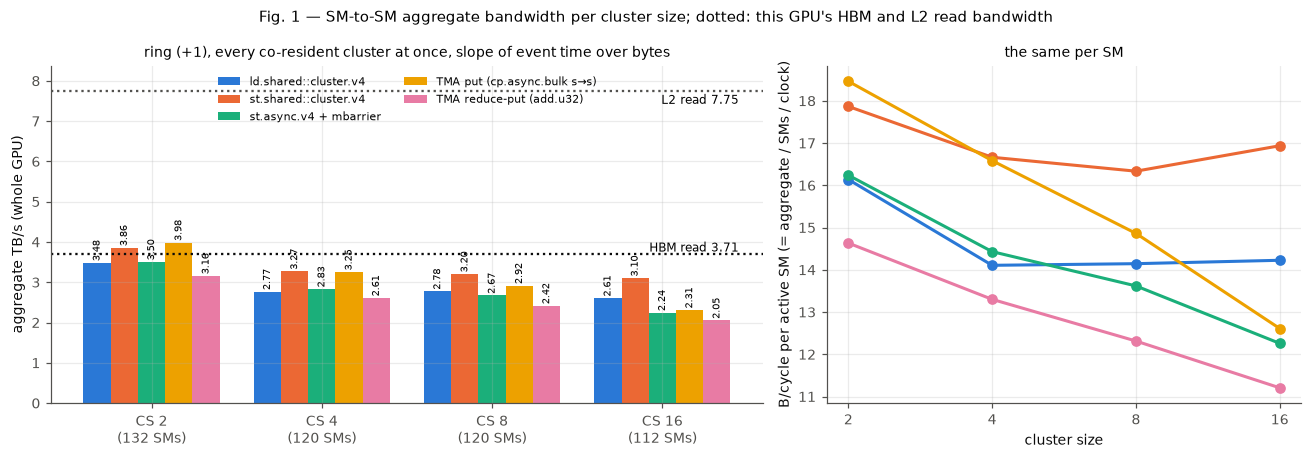

,active SMs,ld.shared::cluster.v4,st.shared::cluster.v4,st.async.v4 + mbarrier,TMA put (cp.async.bulk s→s),TMA reduce-put (add.u32)
cs,,,,,,
2,132,3.483,3.856,3.505,3.984,3.158
4,120,2.768,3.270,2.831,3.254,2.610
8,120,2.775,3.205,2.672,2.916,2.416
16,112,2.605,3.101,2.245,2.309,2.052


kernel,ld,st,st_async,tma_put,tma_red
cs,,,,,
2,3.564,4.045,3.771,4.167,3.265
4,2.803,3.417,3.091,3.405,2.746
8,2.832,3.460,2.893,3.325,2.685
16,2.748,3.367,2.480,2.969,2.459


In [4]:
S = GW[GW.source == "S"].copy()
fig, axs = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1.5, 1]})
ax = axs[0]
w = 0.16
css = [2, 4, 8, 16]
for i, op in enumerate(OPS):
    d = S[S.kernel == op].set_index("cs").reindex(css)
    x = np.arange(len(css)) + (i - 2) * w
    ax.bar(x, d.tbps_slope, w, color=OPC[op], label=OPLAB[op])
    for xx, v in zip(x, d.tbps_slope):
        ax.text(xx, v + 0.04, f"{v:.2f}", ha="center", va="bottom", fontsize=6.5, rotation=90)
ax.axhline(REF["hbm_read_tbps"], color=INK, ls=":", lw=1.5)
ax.text(3.45, REF["hbm_read_tbps"] + 0.05, f"HBM read {REF['hbm_read_tbps']:.2f}", ha="right", fontsize=8)
ax.axhline(REF["l2_read_tbps"], color=INK2, ls=":", lw=1.5)
ax.text(3.45, REF["l2_read_tbps"] - 0.32, f"L2 read {REF['l2_read_tbps']:.2f}", ha="right", fontsize=8)
act = S[S.kernel == "ld"].set_index("cs").active_sms.reindex(css)
ax.set_xticks(range(len(css)), [f"CS {c}\n({int(a)} SMs)" for c, a in zip(css, act)])
ax.set_ylabel("aggregate TB/s (whole GPU)")
ax.set_ylim(0, REF["l2_read_tbps"] * 1.08)
ax.set_title("ring (+1), every co-resident cluster at once, slope of event time over bytes", fontsize=9)
ax.legend(fontsize=7.5, loc="upper center", ncol=2)
ax = axs[1]
for op in OPS:
    d = S[S.kernel == op].set_index("cs").reindex(css)
    ax.plot(css, d.tbps_slope * 1e12 / (d.active_sms * MHZ * 1e6), "o-", color=OPC[op], label=OPLAB[op])
ax.set_xscale("log", base=2); ax.set_xticks(css, [str(c) for c in css])
ax.set_xlabel("cluster size"); ax.set_ylabel("B/cycle per active SM (= aggregate / SMs / clock)")
ax.set_title("the same per SM", fontsize=9)
fig.suptitle("Fig. 1 — SM-to-SM aggregate bandwidth per cluster size; dotted: this GPU's HBM and L2 read bandwidth", fontsize=10)
plt.tight_layout(); plt.show()
t = S.pivot(index="cs", columns="kernel", values="tbps_slope")[OPS]
t.columns = [OPLAB[c] for c in t.columns]
t.insert(0, "active SMs", S[S.kernel == "ld"].set_index("cs").active_sms.astype(int))
display(t.style.format(precision=3).set_caption("Aggregate TB/s (event-time slope over 4–32 passes of 96 KiB per SM, full chip)"))
chk = S.assign(tb_from_cta=S.bpc_cta_median * S.active_sms * MHZ * 1e6 / 1e12)[["kernel", "cs", "tbps_slope", "tb_from_cta"]]
display(chk.pivot(index="cs", columns="kernel", values="tb_from_cta")[OPS].style.format(precision=3)
        .set_caption("Cross-check: per-CTA median B/cycle at 32 passes × active SMs × clock (TB/s)"))

**Reading Fig. 1.**
- **Aggregate.** With every co-resident cluster running a ring, the GPU moves **2.0–4.0 TB/s** through the SM-to-SM network:
  - CS 2: 3.2–4.0 TB/s (132 SMs);
  - CS 4 and 8: 2.4–3.3 TB/s (120 SMs);
  - CS 16: 2.1–3.1 TB/s (112 SMs).
- **Against memory.** That is about the HBM read bandwidth of this card (3.71 TB/s) and one third to one half of its L2 read bandwidth (7.75 TB/s).
- **Ranking.** Plain stores are the fastest generic operation (3.1–3.9 TB/s). The TMA put is the fastest at CS 2 (3.98 TB/s) but falls behind stores at CS 16. The TMA reduce-put is the slowest everywhere.
- **Why the aggregate falls from CS 2 to CS 4 and beyond.** Two effects, each about half of the drop:
  - Fewer SMs take part: CS ≥ 4 cannot use SMs 124–131, CS 16 also not the 12-SM GPC.
  - Each SM gets less once more SMs of its GPC exchange data across TPCs (section 4.2). The CS-2 clusters stay inside a TPC.
- **Event slope vs summed per-SM rates.** The event-time slope is the throughput of the whole launch: it ends when the slowest SM has finished. The cross-check (per-SM rate × SMs) is 1–29 % higher, most for the TMA put at CS 16 (2.97 vs 2.31 TB/s). Under GPC-wide load the SMs do not get equal shares: in one launch some TMA receivers finish their 3 MiB in 102 µs, others in 142 µs (section 4.2, last table).

### 4.2 Per-SM limits: one direction, both directions, one cluster vs the whole GPU, per GPC

In [5]:
rows = []
for op in OPS:
    for pat, k in [("pair_uni", 1), ("pair_bi", 1), ("ring", 1)]:
        for cs in [2, 4, 8, 16]:
            st = "C" if cs == 8 or pat != "ring" else "A"
            try:
                f1, f2 = fit("C" if pat != "ring" else "A", op, pat, k, cs, "single"), None
            except AssertionError:
                continue
            try:
                f2 = fit("C" if pat != "ring" else "A", op, pat, k, cs, "full")
            except AssertionError:
                pass
            rows.append([OPLAB[op], pat, cs, f1.bpc_per_sm, f1.alpha_cycles, f1.rmse_pct, f2.bpc_per_sm if f2 is not None else np.nan,
                         f2.rmse_pct if f2 is not None else np.nan])
T42 = pd.DataFrame(rows, columns=["operation", "pattern", "CS", "single: B/cycle/SM", "single: alpha (cycles)", "single: RMSE %",
                                  "full: B/cycle/SM", "full: RMSE %"])
display(T42.set_index(["operation", "pattern", "CS"]).style.format(precision=2)
        .set_caption("Affine fits over the payload sweep 16–96 KiB (bandwidth side: issuer for ld/st, target for st.async/TMA)"))

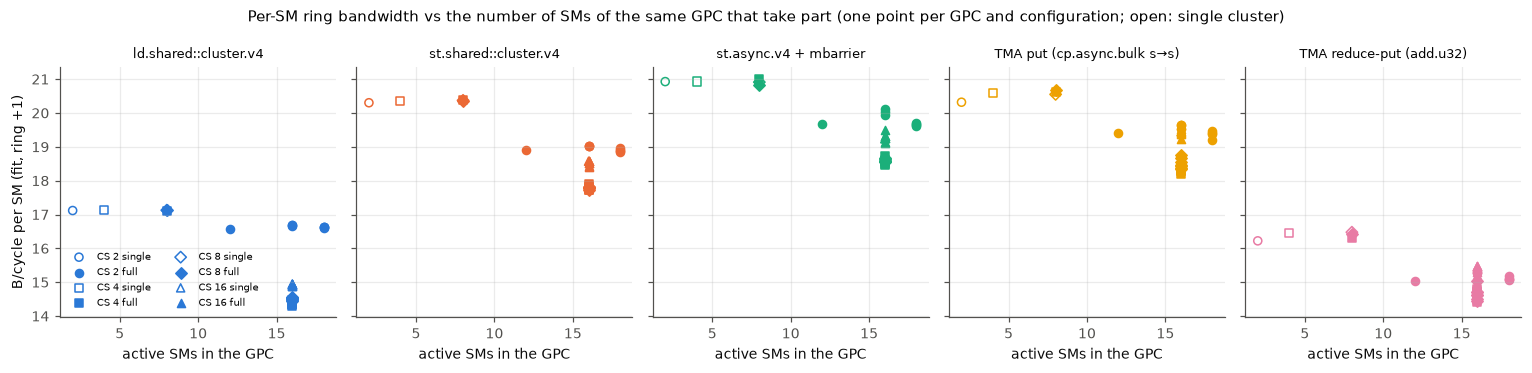

In [6]:
# per-SM rate vs number of active SMs of the same GPC (ring, 96 KiB): single clusters (CS 2/4/8/16) and full waves
d = SA[(SA.step == "A") & (SA.side == SA.stream.map(bw_side))].copy()
d["gpc"] = d.smid.map(GPC)
act = d.groupby(["run_id", "launch_idx", "gpc"]).smid.nunique().rename("active_in_gpc")
d = d.join(act, on=["run_id", "launch_idx", "gpc"])
g = d.groupby(["kernel", "cs", "launch_mode", "gpc", "active_in_gpc", "payload_bytes"]).cycles.median().reset_index()
pg = []
for key, x in g.groupby(["kernel", "cs", "launch_mode", "gpc", "active_in_gpc"]):
    a, b = affine(x.payload_bytes, x.cycles)
    pg.append(list(key) + [1 / b])
PG = pd.DataFrame(pg, columns=["kernel", "cs", "mode", "gpc", "active_in_gpc", "bpc"])
fig, axs = plt.subplots(1, 5, figsize=(14, 3.4), sharey=True)
for ax, op in zip(axs, OPS):
    x = PG[PG.kernel == op]
    for cs, mk in zip([2, 4, 8, 16], "osD^"):
        for mode, fc in [("single", "none"), ("full", None)]:
            y = x[(x.cs == cs) & (x["mode"] == mode)]
            ax.scatter(y.active_in_gpc, y.bpc, marker=mk, s=28, edgecolor=OPC[op], facecolor=fc or OPC[op], label=f"CS {cs} {mode}")
    ax.set_title(OPLAB[op], fontsize=8.5); ax.set_xlabel("active SMs in the GPC")
axs[0].set_ylabel("B/cycle per SM (fit, ring +1)")
axs[0].legend(fontsize=6.5, ncol=2, loc="lower left")
fig.suptitle("Per-SM ring bandwidth vs the number of SMs of the same GPC that take part (one point per GPC and configuration; open: single cluster)", fontsize=9.5)
plt.tight_layout(); plt.show()
display(PG.pivot_table(index=["kernel", "cs", "mode"], columns="gpc", values="bpc").reindex(OPS, level=0).style.format(precision=2, na_rep="")
        .set_caption("Per-GPC fits, ring (+1): B/cycle per SM (columns: GPC)"))
pr = SA[(SA.step == "A") & (SA.cs == 16) & (SA.payload_bytes == 98304) & (SA.side == SA.stream.map(bw_side))]
display(pr.groupby(["kernel", "launch_mode", "rank"]).bpc.median().unstack().reindex(OPS, level=0).style.format(precision=1)
        .set_caption("ring (+1) at CS 16, 96 KiB: B/cycle of each rank (columns; includes the fixed cost), median over clusters, samples, launches"))

**Reading the per-SM numbers.**
- **One direction: 21.2–21.5 B/cycle per SM for every operation.** One SM sending to one peer reaches 21.3–21.5 (ld), 21.2–21.3 (st) and 21.0–21.3 B/cycle (TMA put), with α of 800–3000 cycles and residuals ≤ 1.5 %. The value is the same at every cluster size and with 15 clusters running at once (pair_uni, packed pairs).
- **Both directions.** When the SMs of a pair (or a ring) send and receive at the same time:
  - loads lose 20 %: 17.1 B/cycle per direction;
  - stores and TMA puts lose only 4–5 %: 20.3–20.6.

  A load's request also travels out of the reader, so in pair_bi and ring each SM's outgoing connection carries its own requests next to the replies it serves.
- **Reduce-put and st.async.** The TMA reduce-put delivers 16.2–16.5 B/cycle in a ring, 20 % below the plain put. `st.async` delivers 20.9, like plain stores.
- **GPC contention.** In a ring the per-SM rate depends on how many SMs of the same GPC take part, not on how many clusters there are:
  - With 8 active SMs (one CS-8 cluster, or the 8 cluster-capable SMs of the 12-SM GPC on the full GPU), ld gives 17.1 B/cycle.
  - With 16 active SMs, ld gives 14.4–14.9: one CS-16 cluster, two CS-8 clusters or four CS-4 clusters behave alike, in every 16-SM GPC.
  - Stores (20.4 → 17.8–18.6) and TMA puts (20.6 → 18.3–19.7) drop the same way.
  - CS-2 clusters, whose traffic stays between the two SMs of a TPC, lose less (ld 16.6, st 18.9) even in 18-SM GPCs.
  - Under that load the share is also uneven across the SMs of a cluster: at CS 16, ld ranks get 12.8–14.8 B/cycle and TMA receivers 12.0–15.0 B/cycle at 96 KiB, with a pattern that repeats from cluster to cluster.
- **Fixed cost α.** 800–930 cycles for loads and stores. For `st.async` and TMA it is 1250–2930 cycles and grows with cluster size, because it includes the receiver's mbarrier handling and the first TMA command (≈ 1150 cycles, section 4.6).

### 4.3 Threads and loads in flight (Fig. 2)

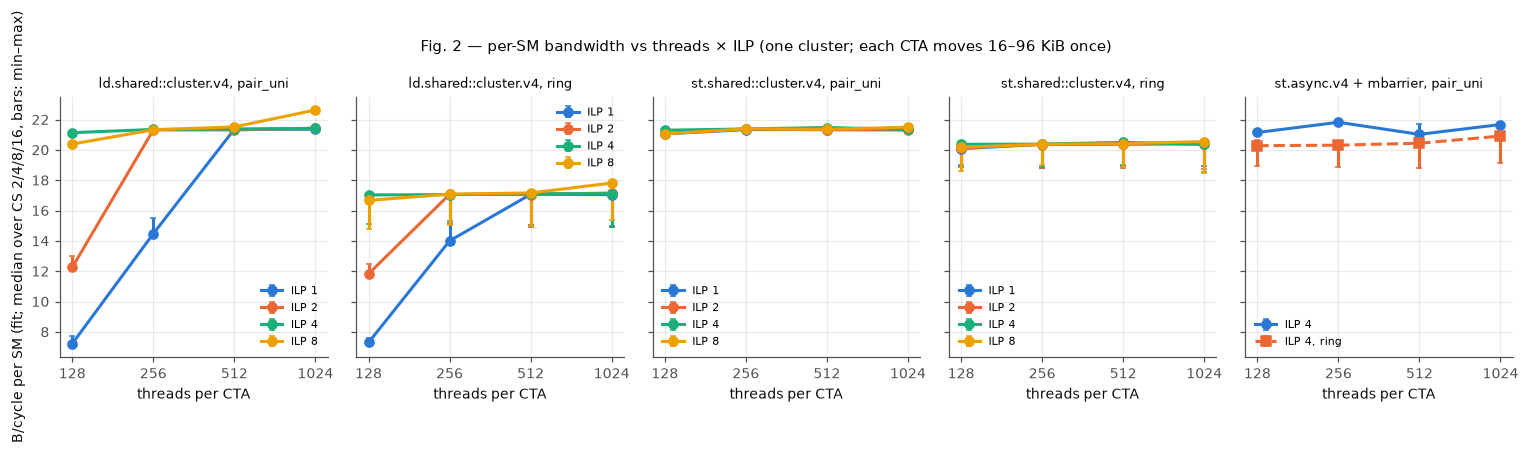

In [7]:
B = BW[BW.step == "B"]
fig, axs = plt.subplots(1, 5, figsize=(14, 3.5), sharey=True)
panels = [("ld", "pair_uni"), ("ld", "ring"), ("st", "pair_uni"), ("st", "ring"), ("st_async", "pair_uni")]
for ax, (op, pat) in zip(axs, panels):
    x = B[(B.kernel == op) & (B.pattern == pat)]
    for i, ilp in enumerate(sorted(x.ilp.unique())):
        y = x[x.ilp == ilp]
        s = y.groupby("threads").bpc_per_sm.agg(["median", "min", "max"])
        ax.errorbar(s.index, s["median"], yerr=[s["median"] - s["min"], s["max"] - s["median"]], fmt="o-", color=C[i], capsize=2,
                    label=f"ILP {ilp}")
    if op == "st_async":
        y = B[(B.kernel == op) & (B.pattern == "ring")].groupby("threads").bpc_per_sm.agg(["median", "min", "max"])
        ax.errorbar(y.index, y["median"], yerr=[y["median"] - y["min"], y["max"] - y["median"]], fmt="s--", color=C[1], capsize=2, label="ILP 4, ring")
    ax.set_xscale("log", base=2); ax.set_xticks([128, 256, 512, 1024], ["128", "256", "512", "1024"])
    ax.set_title(f"{OPLAB[op]}, {pat}", fontsize=8.5); ax.set_xlabel("threads per CTA")
    ax.legend(fontsize=7)
axs[0].set_ylabel("B/cycle per SM (fit; median over CS 2/4/8/16, bars: min–max)")
fig.suptitle("Fig. 2 — per-SM bandwidth vs threads × ILP (one cluster; each CTA moves 16–96 KiB once)", fontsize=10)
plt.tight_layout(); plt.show()
t = B[B.kernel.isin(["ld", "st"])].pivot_table(index=["kernel", "pattern", "threads"], columns=["ilp", "cs"], values="bpc_per_sm")
display(t.style.format(precision=1).set_caption("B/cycle per SM by threads (rows) and (ILP, CS) (columns)"))

**Reading Fig. 2.**
- **Loads are latency-bound until about 8 KiB are in flight per SM.**
  - 128 threads × 1 load × 16 B (2 KiB) give 7.2–7.8 B/cycle, i.e. one round trip of ≈ 280 cycles per 2 KiB.
  - 4 KiB (256 × 1 or 128 × 2) give 12.2–15.5.
  - 8 KiB or more (128 threads × ILP 4, 256 × 2, 512 × 1) reach the 21.3 B/cycle limit.
  - In a ring the same amounts reach 17.1 (both directions).
- **Stores reach the limit with any number of threads.** 21.1–21.5 B/cycle (pair) and 20.1–20.5 (ring) already at 128 threads and ILP 1, because they are posted; `st.async` behaves the same.
- **Cluster size does not matter** except through the GPC effect of section 4.2 (CS 16 ring: ld 14.8–15.4, st 18.5–19.0).
- **Limitation.** At 1024 threads and ILP 8 one step would cover 128 KiB, more than the 96 KiB payload, so the loads in flight are capped by the payload. The fitted 22.6 B/cycle there comes from the payload-dependent number of steps, not from a faster network.

### 4.4 Traffic patterns at CS 8 (Fig. 3)

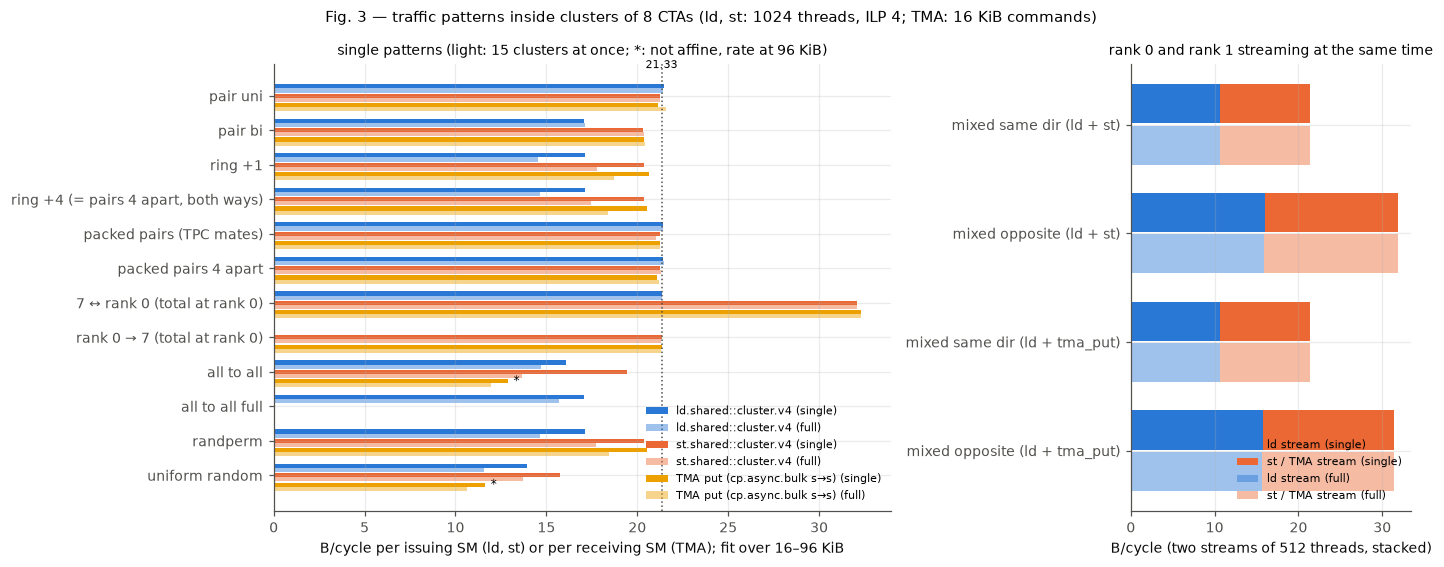

In [8]:
PATS = [("pair_uni", 1), ("pair_bi", 1), ("ring", 1), ("ring", 4), ("packed_pairs", 1), ("packed_pairs", 4), ("broadcast_in", 7),
        ("broadcast_out", 7), ("all_to_all", 1), ("all_to_all_full", 1), ("randperm", 1), ("uniform_random", 1)]
NAMES = {("ring", 1): "ring +1", ("ring", 4): "ring +4 (= pairs 4 apart, both ways)", ("packed_pairs", 1): "packed pairs (TPC mates)",
         ("packed_pairs", 4): "packed pairs 4 apart", ("broadcast_in", 7): "7 ↔ rank 0 (total at rank 0)", ("broadcast_out", 7): "rank 0 → 7 (total at rank 0)"}
C8 = BW[(BW.step == "C") & (BW.cs == 8)]
def val(op, pat, k, mode):
    d = C8[(C8.kernel == op) & (C8.pattern == pat) & (C8.pattern_k == k) & (C8.launch_mode == mode) & (C8.stream == op)]
    if not len(d):
        return np.nan, np.nan, np.nan
    r = d.iloc[0]
    if pat.startswith("broadcast"):   # the shared SM: everything it serves (ld), receives (st/TMA in) or sends (out)
        return shared_total("C", op, pat, k, 8, mode), 0.0, np.nan
    return r.bpc_per_sm, r.rmse_pct, r.bpc_at_max_payload
rows = []
for pat, k in PATS:
    for op in ["ld", "st", "tma_put"]:
        for mode in ["single", "full"]:
            b, rm, bm = val(op, pat, k, mode)
            rows.append([NAMES.get((pat, k), pat.replace("_", " ")), op, mode, b, rm, bm])
PT3 = pd.DataFrame(rows, columns=["pattern", "op", "mode", "bpc", "rmse", "bpc_max"])
mix = []
for op, second in [("mixed_ld_st", "st"), ("mixed_ld_tma", "tma_put")]:
    for pat in ["mixed_same_dir", "mixed_opposite"]:
        for mode in ["single", "full"]:
            d = C8[(C8.kernel == op) & (C8.pattern == pat) & (C8.launch_mode == mode)].set_index("stream")
            mix.append([f"{pat.replace('_', ' ')} (ld + {second})", mode, d.loc["ld"].bpc_per_sm, d.loc[second].bpc_per_sm,
                        d.loc["ld"].rmse_pct, d.loc[second].rmse_pct])
MX = pd.DataFrame(mix, columns=["pattern", "mode", "ld stream", "second stream", "ld RMSE %", "second RMSE %"])
fig, axs = plt.subplots(1, 2, figsize=(13, 5.2), gridspec_kw={"width_ratios": [2.2, 1]})
ax = axs[0]
labels = list(dict.fromkeys(PT3.pattern))
y0 = np.arange(len(labels))
for i, op in enumerate(["ld", "st", "tma_put"]):
    for mode, alpha in [("single", 1.0), ("full", 0.45)]:
        d = PT3[(PT3.op == op) & (PT3["mode"] == mode)].set_index("pattern").reindex(labels)
        v = d.bpc.where(d.rmse <= 2, d.bpc_max)  # not affine: rate at 96 KiB
        ax.barh(y0 + (i - 1) * 0.27 + (0.12 if mode == "full" else -0.0), v, 0.12, color=OPC[op], alpha=alpha,
                label=f"{OPLAB[op]} ({mode})", hatch=None)
        for yy, vv, rm in zip(y0 + (i - 1) * 0.27, v, d.rmse):
            if rm > 2 and mode == "single":
                ax.text(vv + 0.3, yy, "*", fontsize=8, va="center")
ax.set_yticks(y0, labels); ax.invert_yaxis()
ax.set_xlabel("B/cycle per issuing SM (ld, st) or per receiving SM (TMA); fit over 16–96 KiB")
ax.axvline(64 / 3, color=INK2, ls=":", lw=1); ax.text(64 / 3, -0.8, "21.33", fontsize=7.5, ha="center")
ax.legend(fontsize=7, loc="lower right")
ax.set_title("single patterns (light: 15 clusters at once; *: not affine, rate at 96 KiB)", fontsize=9)
ax = axs[1]
yl = list(dict.fromkeys(MX.pattern))
for j, mode in enumerate(["single", "full"]):
    d = MX[MX["mode"] == mode].set_index("pattern").reindex(yl)
    yy = np.arange(len(yl)) + j * 0.38
    ax.barh(yy, d["ld stream"], 0.36, color=OPC["ld"], alpha=1 if mode == "single" else 0.45, label=f"ld stream ({mode})")
    ax.barh(yy, d["second stream"], 0.36, left=d["ld stream"], color=OPC["st"], alpha=1 if mode == "single" else 0.45,
            label=f"st / TMA stream ({mode})")
ax.set_yticks(np.arange(len(yl)) + 0.19, yl); ax.invert_yaxis()
ax.set_xlabel("B/cycle (two streams of 512 threads, stacked)")
ax.legend(fontsize=7, loc="lower right"); ax.set_title("rank 0 and rank 1 streaming at the same time", fontsize=9)
fig.suptitle("Fig. 3 — traffic patterns inside clusters of 8 CTAs (ld, st: 1024 threads, ILP 4; TMA: 16 KiB commands)", fontsize=10)
plt.tight_layout(); plt.show()
display(PT3.pivot_table(index="pattern", columns=["op", "mode"], values="bpc", sort=False).style.format(precision=2, na_rep="")
        .set_caption("Fig. 3 values (affine fits, B/cycle per SM)"))
display(MX.set_index(["pattern", "mode"]).style.format(precision=2))

**Reading Fig. 3.**
- **One sender, one receiver: always ≈ 21.3 B/cycle.** pair_uni, packed pairs with TPC mates and packed pairs 4 ranks apart give the same 21.0–21.5 for ld, st and TMA, single or full. Distance inside the GPC and the TPC relation do not matter while each SM only sends or only receives.
- **Ring, ring +4, randperm, pair_bi.** Every SM sends and receives, and they behave alike: ld 17.1, st 20.4, TMA 20.5 (one cluster); on the full GPU ld 14.5, st 17.8, TMA 18.5–18.7. The partner's position does not matter, only that both directions are used and how busy the GPC is.
- **One SM shared by 7 others (the shared SM's total):**
  - It serves at most **21.3 B/cycle** to 7 readers, and sends at most 21.3 B/cycle to 7 targets, with stores or with TMA.
  - It *receives* up to **32.1–32.3 B/cycle** from 7 writers.

  Sending is limited at about 2/3 of the rated 32 B/cycle, receiving at the rated value.
- **all_to_all / all_to_all_full / uniform_random.**
  - Loads: all_to_all 16.1 (14.7 full), all_to_all_full 17.1 (15.7 full).
  - Stores: all_to_all 19.4 (15.9 full).
  - Random partners lose another 15–25 % (ld 13.9, st 15.8, TMA 15.2): with a new random target for every 16 KiB, some SMs receive from several senders at once while others idle. The profiler shows the busiest receiving SM getting 1.3–1.8× its share with stores and TMA (section 4.11).
  - The TMA all_to_all is limited by command issue at these payloads (7 commands to 7 different targets take ≈ 2950 cycles to issue, section 4.6), so its fit is not affine; its rate at 96 KiB is 12.7 B/cycle.
- **Two streams at once (right panel).**
  - In the same physical direction (rank 1 serves rank 0's loads and writes into rank 0), the two streams share **21.4 B/cycle** (10.7 each). The limit belongs to the sending SM, whichever operation fills it.
  - In opposite directions they reach **31.4–31.9 B/cycle** together (15.7–16.0 each): each SM sends one stream and receives the other, minus the load requests that rank 0 sends.

### 4.5 One SM serving or feeding many (Fig. 4)

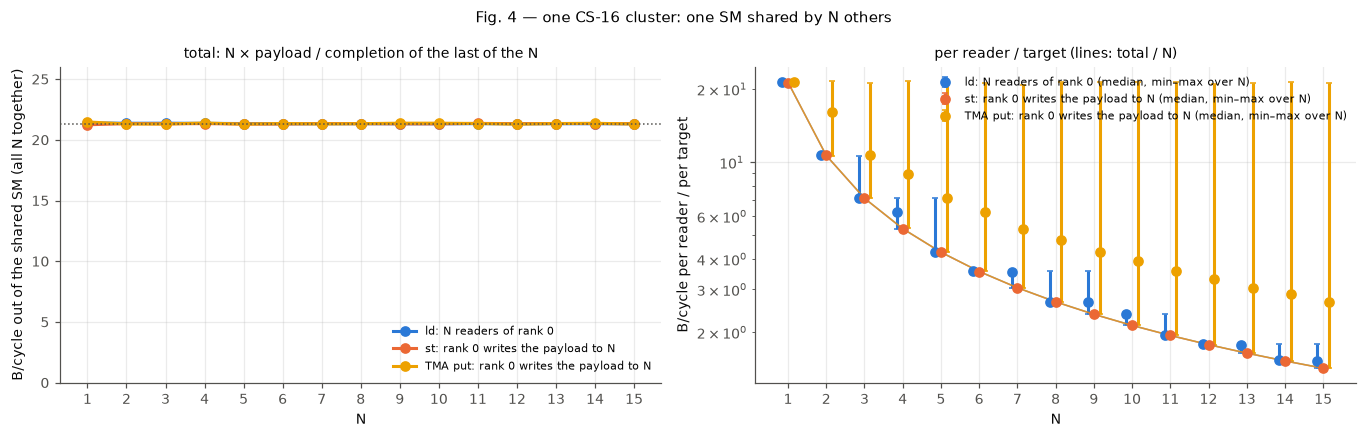

,ld: N readers of rank 0,st: rank 0 writes the payload to N,TMA put: rank 0 writes the payload to N,ld: N readers of rank 0: per-reader min / max,TMA put: rank 0 writes the payload to N: per-reader min / max
1,21.40,21.24,21.48,21.40 / 21.40,21.48 / 21.48
2,21.37,21.33,21.31,10.69 / 10.70,10.65 / 21.51
3,21.37,21.32,21.30,7.13 / 10.62,7.10 / 21.11
4,21.36,21.34,21.39,5.34 / 7.14,5.35 / 21.53
5,21.34,21.30,21.30,4.26 / 7.13,4.26 / 21.20
6,21.32,21.31,21.34,3.55 / 3.57,3.56 / 21.29
7,21.33,21.34,21.31,3.05 / 3.56,3.04 / 20.82
8,21.33,21.33,21.33,2.67 / 3.56,2.67 / 21.39
9,21.32,21.32,21.37,2.37 / 3.56,2.37 / 21.34
10,21.33,21.32,21.37,2.13 / 2.38,2.14 / 21.32


,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
1,21.40,,,,,,,,,,,,,,
2,10.70,10.69,,,,,,,,,,,,,
3,10.62,7.13,7.13,,,,,,,,,,,,
4,7.12,5.34,5.34,7.14,,,,,,,,,,,
5,7.13,4.28,4.27,4.27,4.26,,,,,,,,,,
6,3.55,3.57,3.55,3.56,3.56,3.56,,,,,,,,,
7,3.05,3.55,3.56,3.56,3.56,3.05,3.05,,,,,,,,
8,2.67,2.67,2.67,3.56,3.55,2.68,2.67,2.67,,,,,,,
9,2.67,2.37,2.38,3.56,3.56,2.68,2.69,2.37,2.38,,,,,,
10,2.37,2.14,2.14,2.38,2.37,2.38,2.37,2.14,2.13,2.38,,,,,


In [9]:
D = SA[SA.step == "D"]
fig, axs = plt.subplots(1, 2, figsize=(12.5, 4))
ns = np.arange(1, 16)
series = [("ld", "broadcast_in", "issuer", "ld: N readers of rank 0"), ("st", "broadcast_out", "issuer", "st: rank 0 writes the payload to N"),
          ("tma_put", "broadcast_out", "target", "TMA put: rank 0 writes the payload to N")]
TOT, PER = {}, {}
for op, pat, side, lab in series:
    d = D[(D.kernel == op) & (D.pattern == pat) & (D.side == side)]
    # total rate of the shared SM: all bytes of a sample / the completion of the last reader (target)
    last = d.groupby(["pattern_k", "payload_bytes", "launch_idx", "sample"]).agg(c=("cycles", "max"), b=("bytes_moved", "sum")).reset_index()
    lm = last.groupby(["pattern_k", "payload_bytes"]).agg(c=("c", "median"), b=("b", "median")).reset_index()
    TOT[lab] = pd.Series({k: 1 / affine(x.b, x.c)[1] for k, x in lm.groupby("pattern_k")})
    if op == "st":   # one issuer covers every target: per-target rate = its rate / N
        PER[lab] = pd.DataFrame({"min": TOT[lab] / TOT[lab].index, "median": TOT[lab] / TOT[lab].index, "max": TOT[lab] / TOT[lab].index})
    else:            # per reader (target): its own affine fit
        pr = d.groupby(["pattern_k", "rank", "payload_bytes"]).cycles.median().reset_index()
        f = pd.Series({(k, r): 1 / affine(x.payload_bytes, x.cycles)[1] for (k, r), x in pr.groupby(["pattern_k", "rank"])})
        PER[lab] = f.groupby(level=0).agg(["min", "median", "max"])
    axs[0].plot(TOT[lab].index, TOT[lab], "o-", color=OPC[op], label=lab)
    p = PER[lab]
    axs[1].errorbar(p.index + {"ld": -0.15, "st": 0, "tma_put": 0.15}[op], p["median"], yerr=[p["median"] - p["min"], p["max"] - p["median"]],
                    fmt="o", color=OPC[op], capsize=2, label=lab + " (median, min–max over N)")
cfit = {lab: float(np.mean(TOT[lab])) for lab in TOT}
for lab, (op, *_ ) in zip(TOT, series):
    axs[1].plot(ns, cfit[lab] / ns, "-", color=OPC[op], lw=1, alpha=0.6)
axs[0].axhline(64 / 3, color=INK2, ls=":", lw=1)
axs[0].set_ylim(0, 26); axs[0].set_xlabel("N"); axs[0].set_ylabel("B/cycle out of the shared SM (all N together)")
axs[0].set_title("total: N × payload / completion of the last of the N", fontsize=9); axs[0].legend(fontsize=7.5, loc="lower right")
axs[1].set_yscale("log"); axs[1].set_xlabel("N"); axs[1].set_ylabel("B/cycle per reader / per target"); axs[1].legend(fontsize=7, loc="upper right")
axs[1].set_title("per reader / target (lines: total / N)", fontsize=9)
for ax in axs:
    ax.set_xticks(ns)
fig.suptitle("Fig. 4 — one CS-16 cluster: one SM shared by N others", fontsize=10)
plt.tight_layout(); plt.show()
t = pd.DataFrame({lab: TOT[lab] for lab in TOT})
for lab in PER:
    if not lab.startswith("st"):
        t[lab + ": per-reader min / max"] = [f"{a:.2f} / {b:.2f}" for a, b in zip(PER[lab]["min"], PER[lab]["max"])]
display(t.style.format(precision=2, subset=list(TOT)).set_caption("Total B/cycle out of the shared SM, and the spread of the per-reader (per-target) rates"))
pr = D[(D.kernel == "ld") & (D.pattern == "broadcast_in") & (D.side == "issuer")].groupby(["pattern_k", "rank", "payload_bytes"]).cycles.median().reset_index()
fr = pd.Series({(k, r): 1 / affine(x.payload_bytes, x.cycles)[1] for (k, r), x in pr.groupby(["pattern_k", "rank"])}).unstack()
display(fr.style.format(precision=2, na_rep="").set_caption("ld broadcast: B/cycle of each reader rank (columns) for N readers (rows); ranks 2k, 2k+1 share a TPC, rank 1 is rank 0's TPC mate"))
r = [[OPLAB[op], cs, fit("C", op, "broadcast_in", cs - 1, cs, "single", stream=op).bpc_per_sm * (1 if op in ASYNC else cs - 1)]
     for op in ["st", "tma_put"] for cs in [2, 4, 8, 16]]
display(pd.DataFrame(r, columns=["operation", "CS", "B/cycle into rank 0 (all CS−1 writers together)"]).set_index(["operation", "CS"])
        .style.format(precision=2).set_caption("broadcast_in with stores: one SM receiving from CS − 1 writers"))

**Reading Fig. 4.**
- **The shared SM's total stays at 21.3 B/cycle for every N from 1 to 15** (left), whether N readers load from it or it writes the payload to N targets, with stores or with TMA. The average per reader or per target is therefore 21.3 / N; the fit of c / N gives c = 21.33.
- **The shares are not equal.**
  - Readers of the same SM finish at different times: for N = 3 rank 1 (rank 0's TPC mate) reads at 10.6 B/cycle and ranks 2 and 3 at 7.1. For N = 4 ranks 1 and 4 get 7.1 and ranks 2 and 3 get 5.3.
  - The per-reader rates take values 21.3 / m for small integers m, consistent with a server that alternates between groups of requesters and gives the leftover bandwidth to the remaining readers once one group has finished.
  - With TMA the targets are served one after another in issue order: the first target receives at 21.5, the last at 21.3 / N.
- **Receiving.** One SM accepts 32.1–34.4 B/cycle from 3–15 writers (table), i.e. the rated 32 B/cycle of its incoming connection.

### 4.6 TMA command size (Fig. 5)

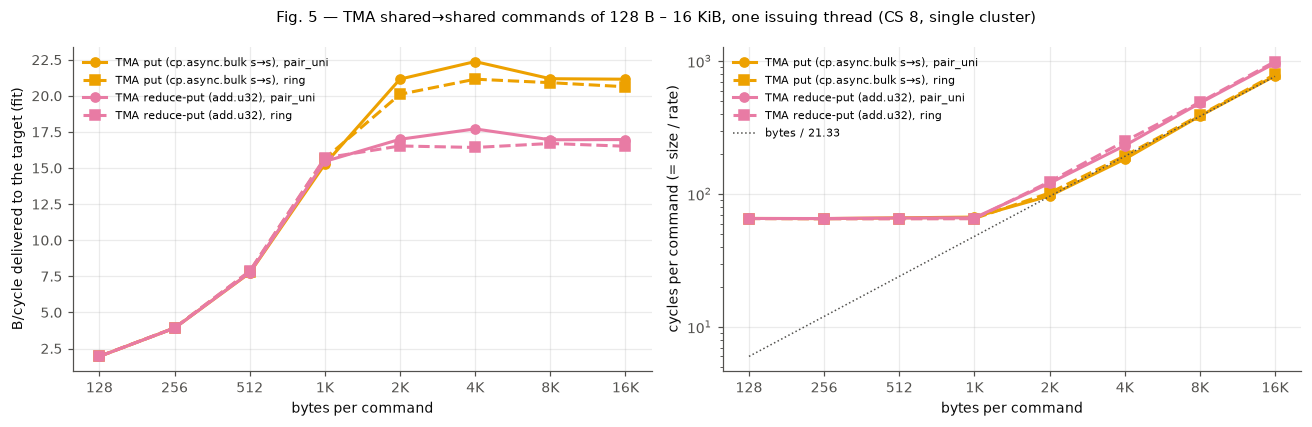

In [10]:
E = FITS[FITS.step == "E"]
fig, axs = plt.subplots(1, 2, figsize=(12, 3.9))
for i, (op, pat) in enumerate([("tma_put", "pair_uni"), ("tma_put", "ring"), ("tma_red", "pair_uni"), ("tma_red", "ring")]):
    d = E[(E.kernel == op) & (E.pattern == pat) & (E.side == "target")].sort_values("chunk_bytes")
    axs[0].plot(d.chunk_bytes, d.bpc_per_sm, "o-" if pat == "pair_uni" else "s--", color=OPC[op], label=f"{OPLAB[op]}, {pat}")
    axs[1].plot(d.chunk_bytes, d.chunk_bytes / d.bpc_per_sm, "o-" if pat == "pair_uni" else "s--", color=OPC[op], label=f"{OPLAB[op]}, {pat}")
c = np.array(sorted(E.chunk_bytes.unique()))
axs[1].plot(c, c / (64 / 3), ":", color=INK2, lw=1, label="bytes / 21.33")
for ax in axs:
    ax.set_xscale("log", base=2); ax.set_xticks(c, [f"{int(x)}" if x < 1024 else f"{int(x) // 1024}K" for x in c]); ax.set_xlabel("bytes per command")
axs[0].set_ylabel("B/cycle delivered to the target (fit)"); axs[0].legend(fontsize=7.5)
axs[1].set_ylabel("cycles per command (= size / rate)"); axs[1].set_yscale("log"); axs[1].legend(fontsize=7.5)
fig.suptitle("Fig. 5 — TMA shared→shared commands of 128 B – 16 KiB, one issuing thread (CS 8, single cluster)", fontsize=10)
plt.tight_layout(); plt.show()
t = E[E.side == "target"].pivot_table(index="chunk_bytes", columns=["kernel", "pattern"], values="bpc_per_sm")
t2 = E[E.side == "target"].pivot_table(index="chunk_bytes", columns=["kernel", "pattern"], values="alpha_cycles")
display(pd.concat({"B/cycle": t, "alpha (cycles)": t2}, axis=1).style.format(precision=2))
# issue side: time of the issuing thread per command, from the issuer records at 96 KiB
s = SA[(SA.step == "E") & (SA.side == "issuer") & (SA.payload_bytes == 98304)]
iss = s.groupby(["kernel", "pattern", "chunk_bytes"]).cycles.median().reset_index()
iss["commands"] = 98304 // iss.chunk_bytes
iss["issue cycles per command"] = iss.cycles / iss.commands
display(iss.pivot_table(index="chunk_bytes", columns=["kernel", "pattern"], values="issue cycles per command").style.format(precision=1)
        .set_caption("Issuing thread: cycles from the barrier to the last command issued, per command (96 KiB)"))
c8 = SA[(SA.step == "C") & (SA.kernel == "tma_put") & (SA.side == "issuer") & (SA.launch_mode == "single") &
        SA.pattern.isin(["ring", "broadcast_out", "all_to_all"])]
ci = c8.groupby(["pattern", "cs", "payload_bytes"]).cycles.median().unstack()
display(ci.style.format(precision=0).set_caption("Issuing thread, cycles until the last command (16 KiB commands): ring = 1 target, "
                                                  "broadcast_out = CS−1 targets × full payload, all_to_all = CS−1 targets × 1/(CS−1)"))

**Reading Fig. 5.**
- **Below 2 KiB a TMA command is limited by its issue cost, not by the network.** Up to 1 KiB every command costs ≈ 65 cycles at the issuing thread. So 128 / 256 / 512 / 1024-byte commands deliver 1.95 / 3.9 / 7.7 / 15.3–15.7 B/cycle.
- **From 2 KiB on the network limit is reached.** Put: 20.1–22.4 B/cycle (21.2 / 20.6 at 16 KiB, pair / ring). Reduce-put: 16.4–17.7 B/cycle; the element-wise add at the destination costs about 20 % of the put's rate.
- **Issue side:**
  - The issuing thread spends ≈ 1150 cycles until the first command of a sample is accepted, the same for any size up to 16 KiB.
  - Further commands to the same target follow every 65 cycles (small commands) to 180 cycles (16 KiB, back-pressured by the network).
  - Each command to a *different* target adds ≈ 270–430 cycles, independent of its size: 7 commands of 2.3 KiB to 7 targets take as long to issue (2950 cycles) as 7 commands of 16 KiB.
  - Spreading a TMA transfer over many destinations is therefore expensive at the issuer. A single thread can still keep the network saturated when the commands to one target are ≥ 2 KiB.

### 4.7 Scheduling policy

In [11]:
rows = []
for op in ["ld", "st", "tma_put"]:
    for cs in [2, 4, 8, 16]:
        for mode in ["single", "full"]:
            r = [OPLAB[op], cs, mode, fit("A", op, "ring", 1, cs, mode).bpc_per_sm]
            for pol in ["Spread", "LoadBalancing"]:
                r.append(fit("F", op, "ring", 1, cs, mode, policy=pol).bpc_per_sm)
            rows.append(r)
display(pd.DataFrame(rows, columns=["operation", "CS", "mode", "Default", "Spread", "LoadBalancing"]).set_index(["operation", "CS", "mode"])
        .style.format(precision=2).set_caption("ring (+1), B/cycle per SM by scheduling policy"))
same = SA[(SA.step.isin(["A", "F"])) & (SA.launch_mode == "single") & (SA["sample"] == 0) & (SA.side == "issuer") & (SA.kernel == "ld")]
pl = same.groupby(["policy", "cs"]).smid.apply(lambda s: ",".join(map(str, sorted(s.unique())))).unstack(0)
display(Markdown("SMs used by the single cluster (ld ring, every launch, every policy):"))
display(pl)

SMs used by the single cluster (ld ring, every launch, every policy):

policy,Default,LoadBalancing,Spread
cs,,,
2,"124,125","124,125","124,125"
4,"0,1,16,17","0,1,16,17","0,1,16,17"
8,"0,1,16,17,32,33,48,49","0,1,16,17,32,33,48,49","0,1,16,17,32,33,48,49"
16,"2,3,18,19,34,35,50,51,64,65,78,79,92,93,106,107","2,3,18,19,34,35,50,51,64,65,78,79,92,93,106,107","2,3,18,19,34,35,50,51,64,65,78,79,92,93,106,107"


**Scheduling policy.**
- Default, Spread and LoadBalancing give the same bandwidth within ±0.2 B/cycle in every configuration, single or full.
- With one CTA per SM (200 KB of shared memory) LoadBalancing cannot place two CTAs of a cluster on one SM.
- A lone cluster lands on the same SMs under every policy and in every launch:
  - CS 2 on SMs 124/125;
  - CS 4 and 8 in the 12-SM GPC (from SM 0);
  - CS 16 in a 16-SM GPC (from SM 2).

### 4.8 A many-block ring launch

In [12]:
P = LA[LA.step == "P1"].copy()
P["tbps"] = P.total_bytes / P.event_ns * 1e-3
t = P.groupby(["kernel", "cs", "passes"]).tbps.median().unstack()
g = GW[GW.source == "P1"].set_index(["kernel", "cs"]).tbps_slope
t["slope (TB/s)"] = g.reindex(t.index)
display(t.style.format(precision=3).set_caption("50 160 blocks × 1024 threads, 16 KiB smem, 2 blocks per SM, ring (+1); "
                                                "columns: passes over the peer's 16 KiB, TB/s = bytes / event time"))
h = MBB.groupby(["kernel", "cs", "passes", "launch_idx"]).blocks.agg(["min", "max", "sum"]).reset_index()
display(Markdown(f"Blocks per SM over all many-block launches: {h['min'].min()}–{h['max'].max()} (every launch: {h['sum'].min()} blocks)."))

Blocks per SM over all many-block launches: 0–588 (every launch: 50160 blocks).

**Many-block ring launch.**
- **The launch.** 50 160 blocks (2 per SM, 16 KiB of shared memory each); every block reads (or writes) its ring partner's 16 KiB 1, 4 or 16 times and exits. Measured only by the cudaEvent pair around the launch.
- **Throughput:**
  - With 16 passes: 3.41 (ld), 3.78 (st) and 4.20 TB/s (TMA put) at CS 2; 2.3–3.3 TB/s at CS 4–16.
  - The slope over the passes (block start and exit removed): 3.66 / 4.07 / 4.72 TB/s at CS 2.
  - With a single pass per block, block scheduling dominates: 1.1–1.75 TB/s.
- **Placement.** At CS ≥ 4 the SMs 124–131 run no block, and at CS 16 neither does the 12-SM GPC: those SMs cannot host such clusters. The other SMs run 230–588 blocks each.

### 4.9 Local shared memory of an SM that is being read remotely (Fig. 6)

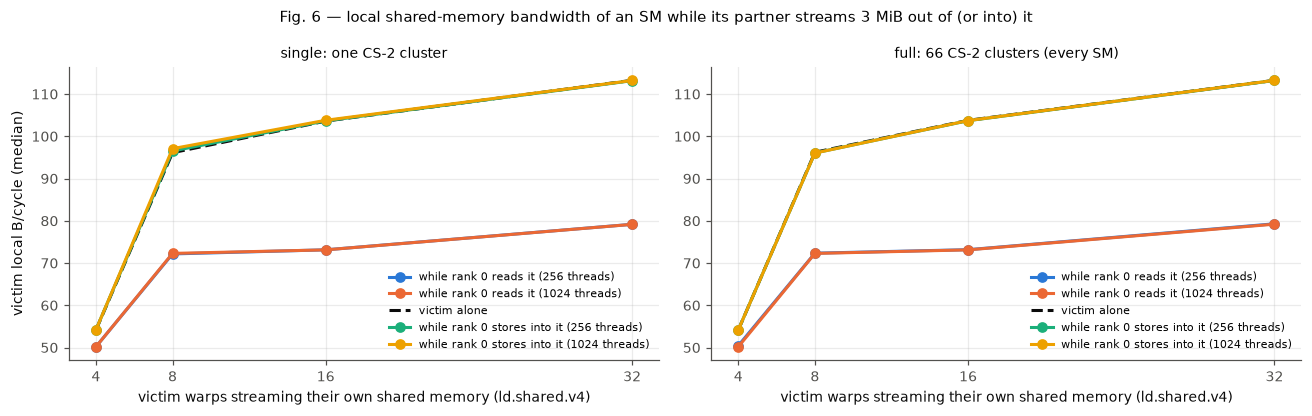

In [13]:
V = VI.copy()
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, mode in zip(axs, ["single", "full"]):
    x = V[V.launch_mode == mode]
    for (kern, rt, on), d in x[x.side == "victim"].groupby(["kernel", "reader_threads", "reader_on"]):
        s = d.groupby("victim_warps").bpc.median()
        lab = "victim alone" if not on else f"while rank 0 {'reads' if kern == 'ld' else 'stores into'} it ({rt} threads)"
        ax.plot(s.index, s, "o-" if on else "--", color=None if on else INK, label=lab)
    ax.set_xlabel("victim warps streaming their own shared memory (ld.shared.v4)"); ax.set_xticks([4, 8, 16, 32])
    ax.set_title(f"{mode}: {'one CS-2 cluster' if mode == 'single' else '66 CS-2 clusters (every SM)'}", fontsize=9)
    ax.legend(fontsize=7)
axs[0].set_ylabel("victim local B/cycle (median)")
fig.suptitle("Fig. 6 — local shared-memory bandwidth of an SM while its partner streams 3 MiB out of (or into) it", fontsize=10)
plt.tight_layout(); plt.show()
t = V.groupby(["launch_mode", "side", "kernel", "reader_threads", "victim_warps"]).bpc.median().unstack()
display(t.style.format(precision=2, na_rep="").set_caption("Median B/cycle (columns: victim warps)"))

**Reading Fig. 6.**
- **Being read costs the serving SM local bandwidth; being written does not.**
  - Alone, the victim's warps stream their own shared memory at 54 / 96 / 104 / 113 B/cycle with 4 / 8 / 16 / 32 warps (the loop itself, with its flag check, limits it below the 128 B/cycle of shared memory).
  - While its partner reads 21.2 B/cycle out of it, the victim gets 50 / 72 / 73 / 79 B/cycle: up to 34 B/cycle less, about 1.6 bytes of local bandwidth per remotely read byte.
  - While its partner writes 21.2 B/cycle into it, the victim's rate is unchanged.
- **The remote reader is never slowed down.** It keeps 21.2 B/cycle with 256 or 1024 threads, alone or against 32 local warps.
- **The full GPU (66 pairs) shows the same numbers.**

### 4.10 SM-to-SM traffic next to SM→L2 traffic in the same GPC (Fig. 7)

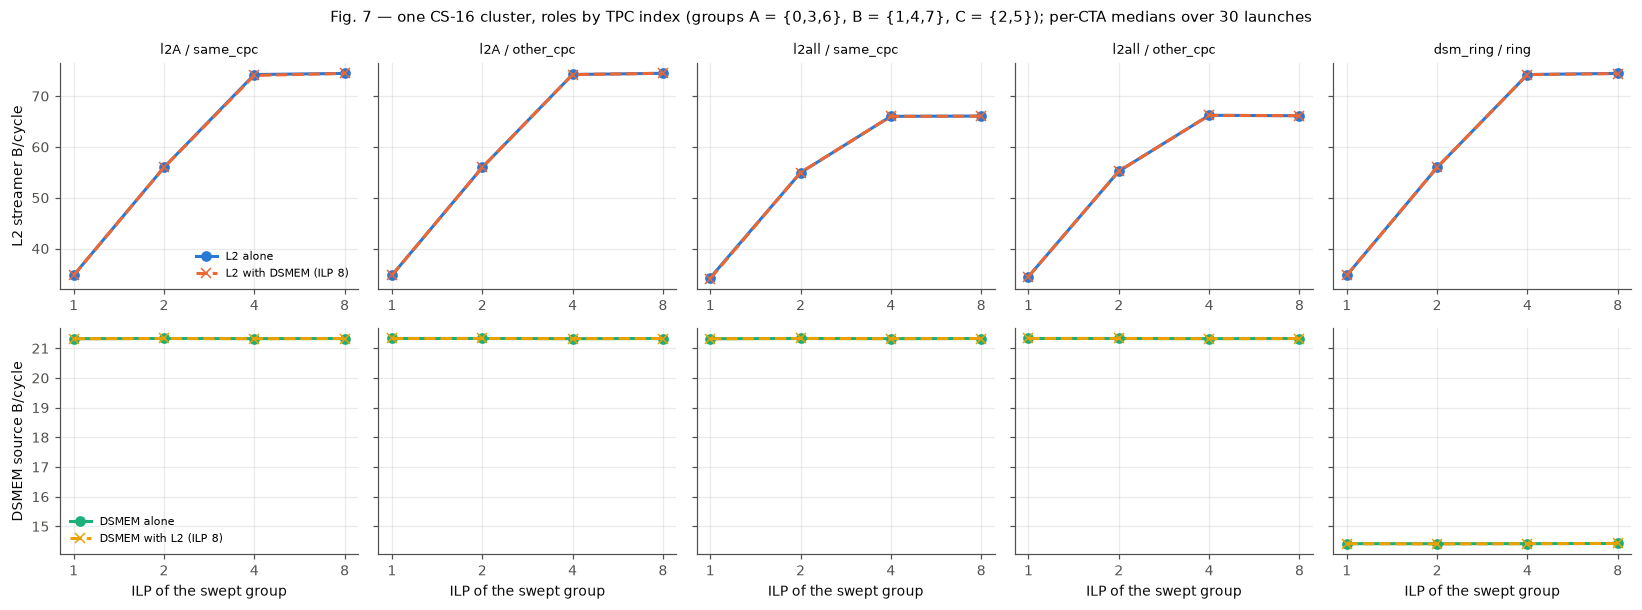

In [14]:
I = IN.copy()
I["combo"] = I.role_map + " / " + I.dsmem_dest
combos = list(dict.fromkeys(I.combo))
fig, axs = plt.subplots(2, len(combos), figsize=(15, 5.6), sharey="row")
for j, cb in enumerate(combos):
    x = I[I.combo == cb]
    ax = axs[0, j]
    a = x[(x.group == "l2") & (x.alone_or_both == "alone")].groupby("ilp_l2").bpc.median()
    b = x[(x.group == "l2") & (x.alone_or_both == "both") & (x.ilp_dsmem == 8)].groupby("ilp_l2").bpc.median()
    ax.plot(a.index, a, "o-", color=C[0], label="L2 alone"); ax.plot(b.index, b, "x--", color=C[1], label="L2 with DSMEM (ILP 8)")
    ax.set_title(cb, fontsize=8.5); ax.set_xscale("log", base=2); ax.set_xticks([1, 2, 4, 8], ["1", "2", "4", "8"])
    ax = axs[1, j]
    a = x[(x.group == "dsmem") & (x.alone_or_both == "alone")].groupby("ilp_dsmem").bpc.median()
    b = x[(x.group == "dsmem") & (x.alone_or_both == "both") & (x.ilp_l2 == 8)].groupby("ilp_dsmem").bpc.median()
    ax.plot(a.index, a, "o-", color=C[2], label="DSMEM alone"); ax.plot(b.index, b, "x--", color=C[3], label="DSMEM with L2 (ILP 8)")
    ax.set_xscale("log", base=2); ax.set_xticks([1, 2, 4, 8], ["1", "2", "4", "8"]); ax.set_xlabel("ILP of the swept group")
axs[0, 0].set_ylabel("L2 streamer B/cycle"); axs[1, 0].set_ylabel("DSMEM source B/cycle")
axs[0, 0].legend(fontsize=7); axs[1, 0].legend(fontsize=7)
fig.suptitle("Fig. 7 — one CS-16 cluster, roles by TPC index (groups A = {0,3,6}, B = {1,4,7}, C = {2,5}); per-CTA medians over 30 launches", fontsize=10)
plt.tight_layout(); plt.show()
k = ["combo", "group", "ilp_l2", "ilp_dsmem", "alone_or_both"]
t = I.groupby(k).agg(ctas=("smid", "nunique"), bpc=("bpc", "median"), lat=("loaded_latency_cycles", "median")).reset_index()
alone_l2 = t[(t.group == "l2") & (t.alone_or_both == "alone")].set_index(["combo", "ilp_l2"]).bpc
alone_ds = t[(t.group == "dsmem") & (t.alone_or_both == "alone")].set_index(["combo", "ilp_dsmem"]).bpc
both = t[t.alone_or_both == "both"].copy()
both["alone"] = [alone_l2[(c, il)] if g == "l2" else alone_ds[(c, idm)] for c, g, il, idm in zip(both.combo, both.group, both.ilp_l2, both.ilp_dsmem)]
both["change %"] = 100 * (both.bpc / both.alone - 1)
display(both.set_index(k).style.format(precision=2).set_caption("Both groups running: per-CTA B/cycle, group alone at the same ILP, change"))
lat = t.pivot_table(index=["combo", "group", "alone_or_both"], columns=["ilp_l2", "ilp_dsmem"], values="lat")
display(lat.style.format(precision=0, na_rep="").set_caption("Mean loaded latency per ILP group (cycles; columns: L2 ILP, DSMEM ILP)"))

**Reading Fig. 7.**
- **No interference between SM-to-SM and SM→L2 traffic in the same GPC, in any role map.**
  - With both groups running, every group's rate stays within 0.5 % of its rate alone (table; most changes are below 0.1 %), and its loaded latency is unchanged.
  - L2 streamers get 74.4 B/cycle each (6 SMs) or 66.1–66.6 (10 SMs; 1.08 TB/s for the GPC).
  - DSMEM sources keep 21.33 (3 sources) or 14.42 B/cycle (10 SMs in a ring).
- **No CPC-group effect.** Whether the DSMEM server is in the source's TPC-index group (`same_cpc`) or in another group (`other_cpc`) changes nothing.
- **Limitation of the DSMEM ILP axis.** With 1024 threads × 16 B, even one load in flight per thread (16 KiB per SM) saturates a DSMEM source. The swept ILP therefore changes only its loaded latency (713 → 3586 cycles per group from ILP 1 to 8), not its bandwidth. The L2 side spans 35 → 74 B/cycle.

### 4.11 Hardware counters (Nsight Compute)

In [15]:
N = NC.copy()
for c in N.columns:
    if c.startswith(("l1tex__", "sm__", "gpu__")):
        N[c] = pd.to_numeric(N[c], errors="coerce")
N["out/issuer"] = N["l1tex__m_l1tex2xbar_write_bytes_mem_dshared.sum"] / N.issuer_bytes
N["in/issuer"] = N["l1tex__m_xbar2l1tex_read_bytes_mem_dshared.sum"] / N.issuer_bytes
N["out max/avg"] = N["l1tex__m_l1tex2xbar_write_bytes_mem_dshared.max"] / N["l1tex__m_l1tex2xbar_write_bytes_mem_dshared.avg"]
N["in max/avg"] = N["l1tex__m_xbar2l1tex_read_bytes_mem_dshared.max"] / N["l1tex__m_xbar2l1tex_read_bytes_mem_dshared.avg"]
N["out max (B)"] = N["l1tex__m_l1tex2xbar_write_bytes_mem_dshared.max"]
N["in max (B)"] = N["l1tex__m_xbar2l1tex_read_bytes_mem_dshared.max"]
inst = ["sm__sass_inst_executed_op_dshared_ld.sum", "sm__sass_inst_executed_op_dshared_st.sum", "sm__sass_inst_executed_op_dshared_stas.sum",
        "sm__sass_inst_executed_op_dshared_tma_st.sum", "sm__sass_inst_executed_op_dshared_tma_red.sum"]
show = ["kernel", "pattern", "pattern_k", "launch_mode", "issuer_bytes", "out/issuer", "in/issuer", "out max (B)", "in max (B)", "out max/avg", "in max/avg"] + inst
t = N[show].rename(columns={c: c.split("op_dshared_")[1].replace(".sum", "") + " instr" for c in inst})
display(t.set_index(["kernel", "pattern", "pattern_k", "launch_mode"]).style.format(precision=2))
pk = [c for c in N.columns if c.endswith(".peak_sustained")]
display(N[pk].drop_duplicates().T.rename(columns=lambda c: "value").style.format(precision=2).set_caption("Rated peaks per SM per cycle reported by ncu"))

,value
l1tex__m_l1tex2xbar_write_bytes_mem_dshared.avg.peak_sustained,32
l1tex__m_l1tex2xbar_write_bytes_mem_dshared.max.peak_sustained,32
l1tex__m_l1tex2xbar_write_bytes_mem_dshared.min.peak_sustained,32
l1tex__m_l1tex2xbar_write_bytes_mem_dshared.sum.peak_sustained,4224
l1tex__m_xbar2l1tex_read_bytes_mem_dshared.avg.peak_sustained,32
l1tex__m_xbar2l1tex_read_bytes_mem_dshared.max.peak_sustained,32
l1tex__m_xbar2l1tex_read_bytes_mem_dshared.min.peak_sustained,32
l1tex__m_xbar2l1tex_read_bytes_mem_dshared.sum.peak_sustained,4224


**Reading the counters.**
- **Rated limits.** The profiler rates both SM-to-SM connections of every SM at **32 B/cycle** (`l1tex__m_l1tex2xbar_write_bytes_mem_dshared` and `…xbar2l1tex_read_bytes_mem_dshared`, `.peak_sustained`). Measured, an SM receives at that rate (32.1–34.4 B/cycle from several writers) but sends at most 21.3 B/cycle, i.e. 2/3 of it, for loads, stores, `st.async` and TMA alike.
- **Byte counters.**
  - Both counters count exactly the payload: 1.00 × the bytes the CTAs moved, for every operation. For `all_to_all` it is 1.00–1.06 ×, because of partial 32-byte sectors at the split points.
  - They are charged to the SM that *receives* the data (the reader for loads, the owner for stores and TMA): `.max` equals one SM's payload in pair_uni, and equals rank 0's 7 × payload when 7 writers store into it.
  - Request packets of loads are not visible in them.
- **Hot spots.** With uniform_random partners the busiest receiving SM got 1.33 × (st), 1.50 × (TMA) and 1.83 × (`st.async`) its share (`.max/.avg` = 22–30 vs 16.5 for an even spread). Loads show no hot spot in these counters, because they are charged to the reader, which always reads its own payload.
- **Instruction counts.** One `dshared_ld`/`st`/`stas` per warp-level 16-byte access and one `tma_st`/`tma_red` per bulk command (6 per 96 KiB at 16 KiB per command).

## 5. Insights

1. **An SM sends at most 21.3 B/cycle into the SM-to-SM network and receives up to 32 B/cycle.**
   - The send limit is the same for loads (where the owner sends the reply), stores, `st.async` and TMA puts, at every cluster size and distance, and for one or many destinations: an SM serving 15 readers or writing to 15 targets still moves 21.3 B/cycle in total.
   - It is 2/3 of the 32 B/cycle the hardware's counters rate for the connection. The receive side reaches the rated 32 B/cycle when several SMs write into one.
   - For a stacked-GPC model, this is a per-SM output port of 21.3 B/cycle (35 GB/s at 1635 MHz) and an input port of 32 B/cycle.
2. **Traffic in both directions costs loads 20 %, stores and TMA 4–5 %.** A reader's requests leave through the same outgoing connection that carries the replies it serves to others. Exchanges built on writes (stores, `st.async`, TMA puts) therefore use the network better than exchanges built on remote reads: 20.3–20.6 vs 17.1 B/cycle per SM in a ring.
3. **The GPC shares capacity when many of its SMs exchange data across TPCs.**
   - Per-SM rates fall 10–15 % from 8 to 16 active SMs (ld 17.1 → 14.4–14.9, st 20.4 → 17.8–18.6), and the shares become uneven, so the slowest SM sets the completion time.
   - Pairs inside a TPC lose less. Pure one-way traffic (half of the SMs sending) is not affected at all.
   - The number of clusters and the scheduling policy do not matter.
4. **GPU-wide, SM-to-SM bandwidth equals HBM bandwidth, not L2 bandwidth.**
   - 2.0–4.0 TB/s for a ring over all co-resident clusters: highest at CS 2 (TMA put 3.98, st 3.86 TB/s), 2.1–3.1 TB/s at CS 16, where only 112 SMs can take part.
   - That is about the 3.71 TB/s of HBM read and 1/3–1/2 of the 7.75 TB/s of L2 read.
   - DSMEM's advantage is latency and the absence of L2 traffic (Fig. 7 shows the two do not interfere), not raw aggregate bandwidth.
5. **TMA shared→shared copies are cheap to issue only for large commands to one target.**
   - Commands ≤ 1 KiB are issue-bound at ≈ 65 cycles each; 2 KiB or more reach the network limit.
   - The first command after a barrier takes ≈ 1150 cycles, and every change of destination adds ≈ 270–430 cycles.
   - The reduce-put is limited to ≈ 16.5–17.7 B/cycle.
6. **Remote reads take shared-memory bandwidth from the owner; remote writes do not.** Serving 21 B/cycle of remote reads cost the owner up to 34 B/cycle of its local streaming bandwidth. Producer/consumer exchanges that push data (stores, TMA puts) leave the receiver's own shared-memory bandwidth intact.

**Limitations and anomalies.**
- The payload is at most 96 KiB per pass. At 1024 threads with ILP ≥ 4 the loads in flight are capped by the payload, which also makes the 1024-thread ILP-8 load fits read 22.6 B/cycle.
- 33 of the 642 bandwidth fits have a residual RMSE above 2 % (largest 4.6 %). They are the TMA all_to_all and uniform_random points, the opposite-direction mixed streams, the 128-thread ILP-8 loads and a few full-GPU points. For TMA all_to_all the fitted slope is not a rate, because command issue dominates the small payloads; its 96-KiB rate is shown instead.
- The CPC test uses the TPC-index-mod-3 grouping as a hypothesis; no grouping effect was found.
- The DSMEM ILP axis of the interference test is flat because a single load in flight per thread already saturates a source.
- The GMEM reference lines come from a separate benchmark run on this card with the same clock lock, not from these launches.